In [26]:
import pandas as pd

In [27]:
df = pd.read_csv(r"C:\Users\Aless\Downloads\credit_card_data.csv")
df.head(2)

,age,annual_income_k,num_transactions,night_transactions,foreign_transactions,monthly_spend,is_fraud
0,24,60,60,3,0,1935,0
1,55,112,49,4,1,2193,0


## 1. Setup & Data Inspection
Check `scikit-learn` version, configure Seaborn themes, and inspect the dataset structure.
* **Target for Classification (0 or 1):** `is_fraud` (170 non-fraud, 30 fraud)
* **Target for Linear Regression (Continuous):** `monthly_spend` ($438 to $2,503)

In [28]:
import sklearn
import seaborn as sns
import matplotlib.pyplot as plt

print("Scikit-learn version:", sklearn.__version__)

# Set standard theme for all plots
sns.set_theme(style="white", rc={"figure.figsize": (12, 6)})
sns.set_context("notebook", font_scale=1.25, rc={"lines.linewidth": 2.5})

Scikit-learn version: 1.9.1


In [29]:
# Check total rows and column names (Activity 7.1 style)
print(f"Rows: {len(df)}")
print(f"Columns ({len(df.columns)}):", ", ".join(df.columns))

# Check data types and missing values (sklearn requires 0 missing values and numeric types)
print("\nMissing values per column:\n", df.isnull().sum())

Rows: 200
Columns (7): age, annual_income_k, num_transactions, night_transactions, foreign_transactions, monthly_spend, is_fraud

Missing values per column:
 age                     0
annual_income_k         0
num_transactions        0
night_transactions      0
foreign_transactions    0
monthly_spend           0
is_fraud                0
dtype: int64


## 2. Exploratory Visualizations (Pattern Recognition)
Before building a model, we visualize relationships between predictors and the target (`is_fraud`):
1. **`sns.countplot`**: Best for discrete/categorical variables (e.g., `foreign_transactions`).
2. **`sns.histplot` (Overlaid)**: Shows count distributions for two groups (`hue="is_fraud"`).
3. **`sns.histplot` (`multiple="fill"`)**: Shows **proportion / rate** (0.0 to 1.0) per bin—useful when classes are imbalanced.
4. **`sns.relplot` & `sns.displot`**: Multi-variable facet grids across columns (`col=`).

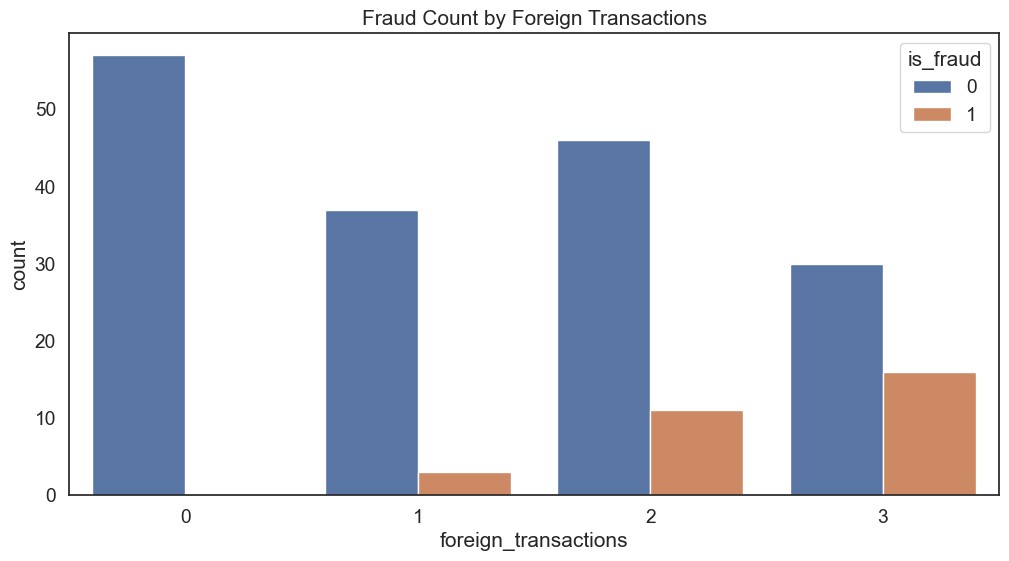

In [30]:
# 1) Bar chart of fraud counts by number of foreign transactions
# Replace x with any discrete/categorical column, and hue with the target column
sns.countplot(data=df, x="foreign_transactions", hue="is_fraud")
plt.title("Fraud Count by Foreign Transactions")
plt.show()

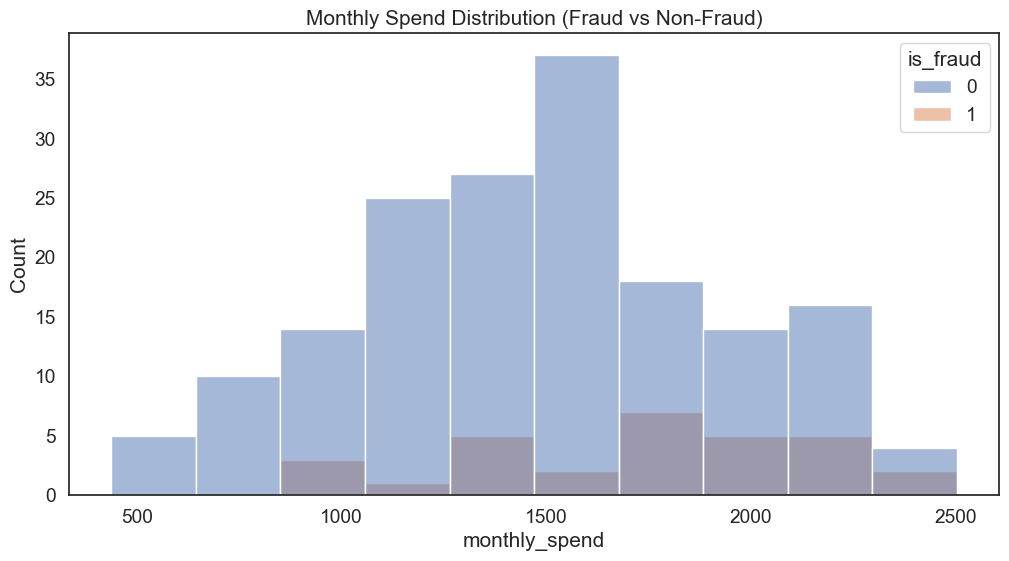

In [31]:
# 2) Overlaid histogram of a continuous variable (monthly_spend) split by target (is_fraud)
sns.histplot(data=df, x="monthly_spend", hue="is_fraud")
plt.title("Monthly Spend Distribution (Fraud vs Non-Fraud)")
plt.show()

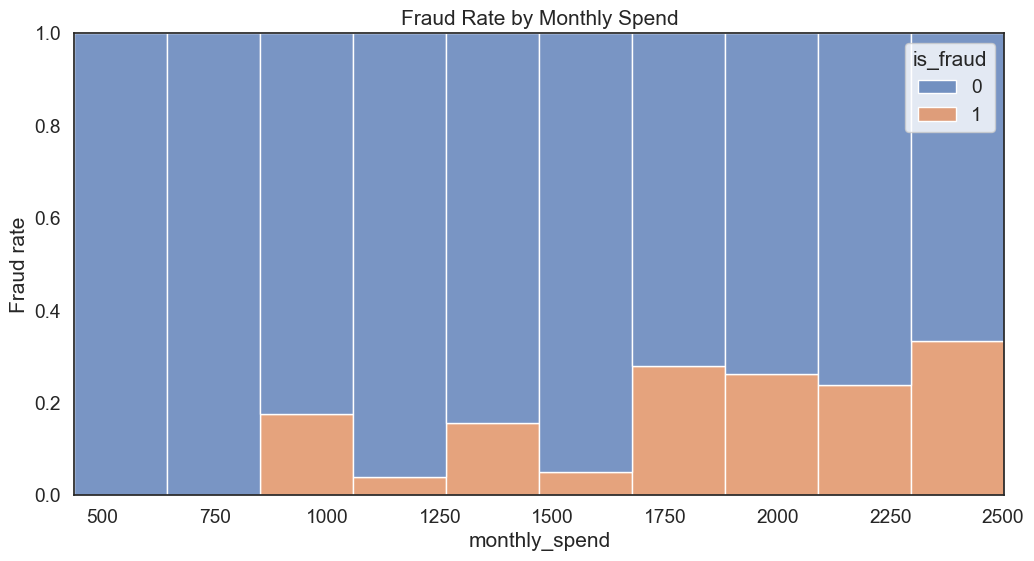

In [32]:
# 3) Proportion histogram: multiple="fill" normalizes bars to 100% (1.0) to show the exact rate per bin
sns.histplot(data=df, x="monthly_spend", hue="is_fraud", multiple="fill").set_ylabel("Fraud rate")
plt.title("Fraud Rate by Monthly Spend")
plt.show()

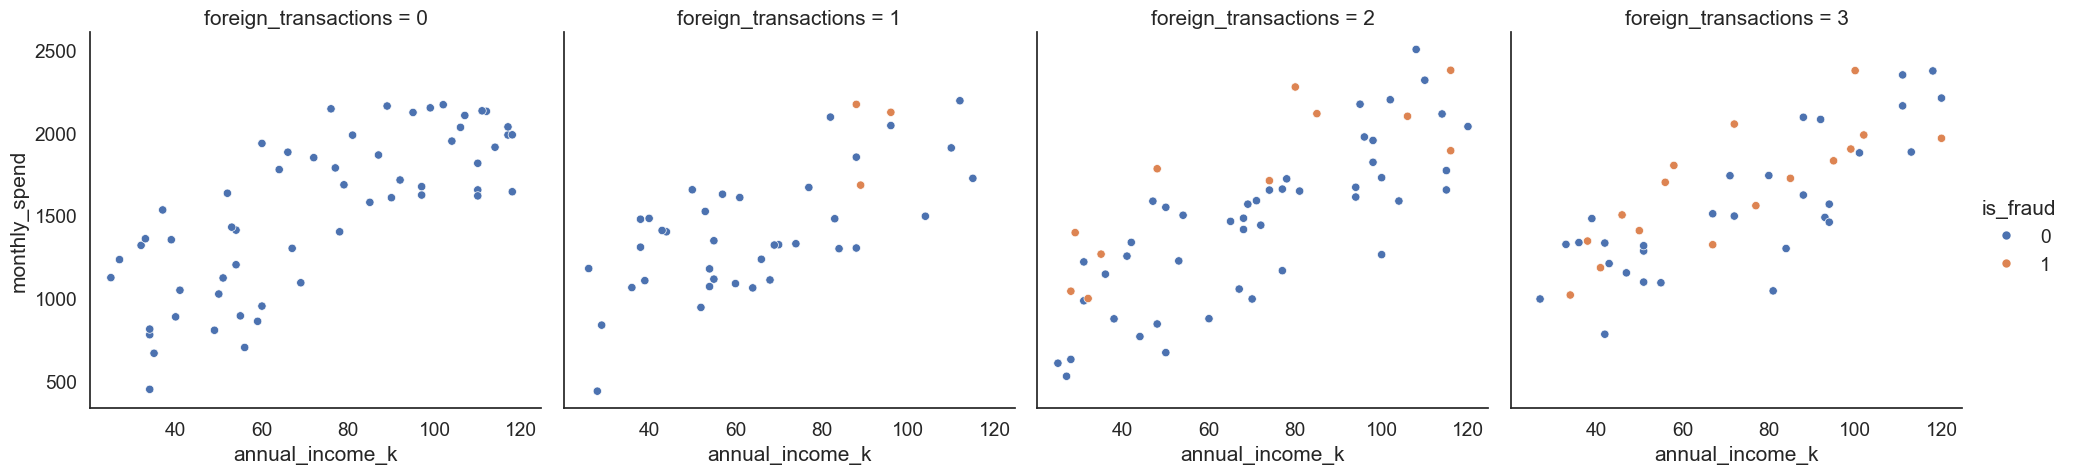

In [33]:
# 4) Scatter plot of two continuous variables, colored by target (hue), split into panels by a category (col)
sns.relplot(
    data=df,
    x="annual_income_k",
    y="monthly_spend",
    hue="is_fraud",
    col="foreign_transactions",
    kind="scatter"
)
plt.show()

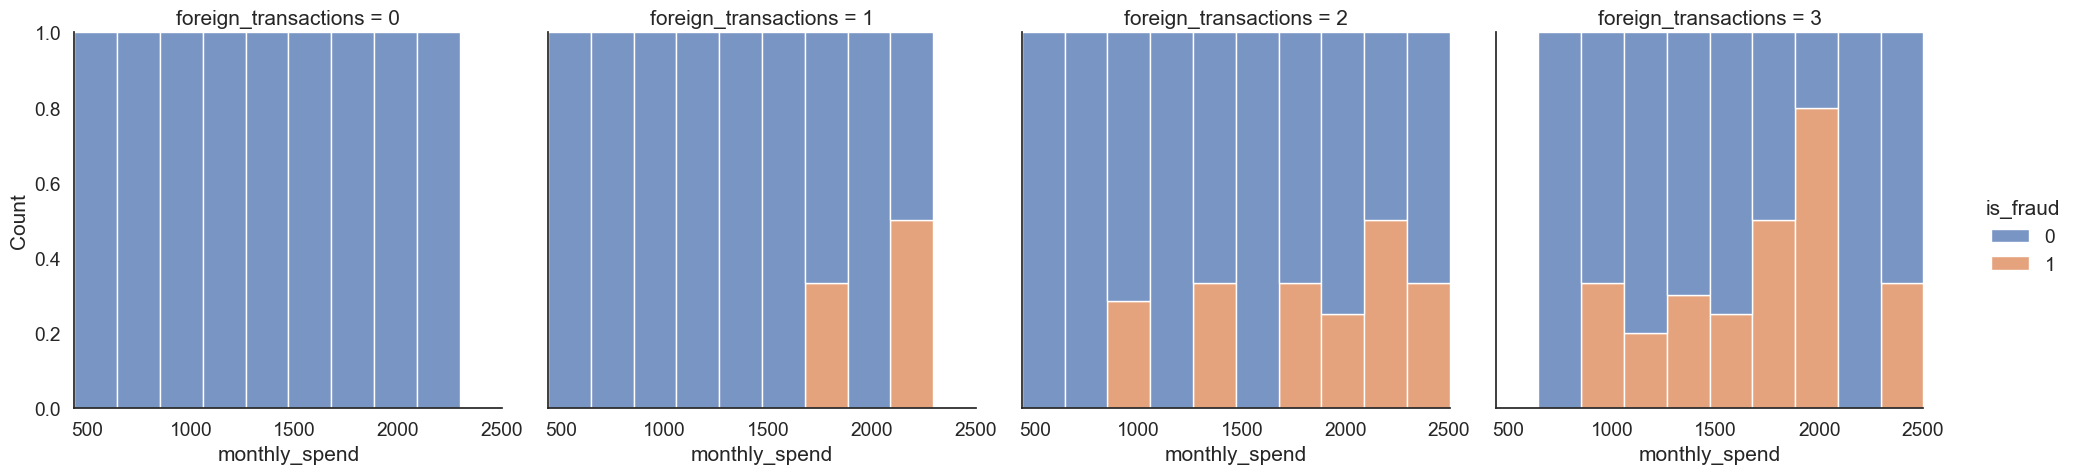

In [34]:
# 5) Separate proportion histograms for each category value using displot
sns.displot(
    data=df,
    x="monthly_spend",
    hue="is_fraud",
    col="foreign_transactions",
    kind="hist",
    multiple="fill"
)
plt.show()

## 3. Data Preparation for Scikit-Learn
`scikit-learn` requires:
1. **No missing values** (`.fillna()`).
2. **All numeric predictors** (`pd.get_dummies()` if you have text/categorical columns).
3. **Separated `X` (predictors) and `y` (target)**.
4. **Data partitioning**: Holdout set (20% untouched until the very end) + Train/Test split (60% train, 40% test).

In [35]:
# Make a copy so we don't alter the original df
sklearn_df = df.copy()

# A) IF A NUMERIC COLUMN HAS MISSING VALUES: fill with median
# sklearn_df["col_name"] = sklearn_df["col_name"].fillna(sklearn_df["col_name"].median())

# B) IF TARGET IS TEXT (e.g. 'Yes'/'No'): map to 1 and 0
# sklearn_df["target"] = sklearn_df["target"].map({"No": 0, "Yes": 1})

# C) IF PREDICTORS CONTAIN TEXT/CATEGORIES: convert to 1/0 dummy columns (drop ID columns first!)
# X = pd.get_dummies(X, drop_first=True, dtype=int)

In [36]:
from sklearn.model_selection import train_test_split

# 1) Manually keep 20% holdout data for final out-of-sample evaluation (Activity 7.2)
holdout = sklearn_df.sample(frac=0.2, random_state=22804)

# 2) Remove holdout rows from the main dataset
df_main = sklearn_df.drop(holdout.index)

# 3) Separate predictors (X) and target variable (y)
X = df_main.drop(columns=["is_fraud"])         # all columns except target (and drop IDs if any exist)
y = df_main["is_fraud"]                        # target column only

X_holdout = holdout.drop(columns=["is_fraud"]) # holdout predictors
y_holdout = holdout["is_fraud"]                # holdout target

In [37]:
# Split remaining data into 60% training and 40% testing (Activity 7.2 setup)
# stratify=y ensures both train and test sets have the exact same percentage of fraud (15%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.6,     # or use test_size=0.2 for an 80/20 split (Activity 7.1)
    random_state=22804, # fixed seed for reproducible quiz answers
    stratify=y
)

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Holdout data:", X_holdout.shape)

Training data: (96, 6)
Test data: (64, 6)
Holdout data: (40, 6)


## 4. Logistic Regression (Classification)
Used when the target `y` is **categorical/binary** (e.g., `is_fraud` = `0` or `1`, `Churn` = `Yes` or `No`).
* `.fit(X_train, y_train)`: Trains the model.
* `.predict(X_test)`: Predicts class labels (`0` or `1`) -> used for `accuracy_score`.
* `.predict_proba(X_test)[:, 1]`: Predicts probability of class `1` (`0.0` to `1.0`) -> used for `roc_auc_score`.

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

# 1) Create the Logistic Regression model (max_iter=1000 prevents convergence warnings)
lr_model = LogisticRegression(max_iter=1000, random_state=22804)

# 2) Train the model on training data
lr_model.fit(X_train, y_train)

# 3) Predict class labels (0/1) and probabilities (0.0 to 1.0) on test data
lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

# 4) Evaluate performance
print("Logistic Regression Test Accuracy:", accuracy_score(y_test, lr_predictions))
print("Logistic Regression Test AUC:", roc_auc_score(y_test, lr_probabilities))

Logistic Regression Test Accuracy: 0.921875
Logistic Regression Test AUC: 0.9674099485420241


In [39]:
# Inspect which features push fraud probability up (positive) or down (negative)
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_model.coef_[0]
}).sort_values(by="Coefficient", ascending=False)
print(coef_df)

# View actual vs predicted side-by-side (like PyCaret's predict_model table)
results_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted_Label": lr_predictions,
    "Predicted_Probability": lr_probabilities.round(3)
})
results_df.head()

                Feature  Coefficient
4  foreign_transactions     2.098064
3    night_transactions     1.036046
5         monthly_spend     0.017271
0                   age     0.012696
1       annual_income_k    -0.210662
2      num_transactions    -0.270719


,Actual,Predicted_Label,Predicted_Probability
29,0,0,0.000
61,1,1,0.993
183,0,0,0.001
177,0,0,0.008
91,0,0,0.059


## 5. Random Forest, Cross-Validation & Hyperparameter Tuning
Used in Activity 7.2 to capture complex non-linear patterns:
1. **`cross_val_score`**: Splits `X_train` into 5 folds, training on 4 and validating on 1 repeatedly to get a reliable baseline AUC.
2. **`RocCurveDisplay`**: Plots True Positive Rate vs. False Positive Rate.
3. **`RandomizedSearchCV`**: Automatically tests multiple hyperparameter settings across 5 folds to find the best model.

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, RandomizedSearchCV
from sklearn.metrics import RocCurveDisplay

# 1) Initialize baseline Random Forest model
rf_model = RandomForestClassifier(random_state=22804)

# 2) Evaluate baseline model using 5-fold cross-validation on training data
cv_auc = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

print("5-Fold CV AUC scores:", cv_auc)
print("Mean CV AUC:", cv_auc.mean())

5-Fold CV AUC scores: [1.         0.91666667 0.97916667 0.97916667 0.96666667]
Mean CV AUC: 0.9683333333333334


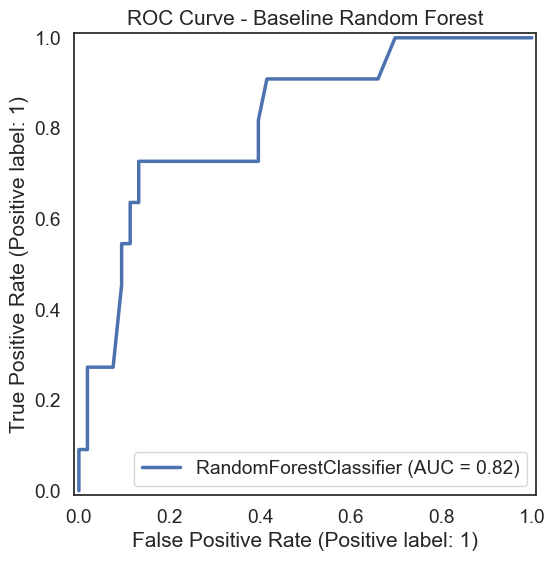

In [41]:
# Train the baseline Random Forest on all training data and plot ROC curve on test data
rf_model.fit(X_train, y_train)

RocCurveDisplay.from_estimator(rf_model, X_test, y_test)
plt.title("ROC Curve - Baseline Random Forest")
plt.show()

In [42]:
# 1) Define hyperparameter grid to search
parameters = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10]
}

# 2) Search 10 random combinations using 5-fold cross-validation
tuning = RandomizedSearchCV(
    RandomForestClassifier(random_state=22804),
    param_distributions=parameters,
    n_iter=10,
    cv=5,
    scoring="roc_auc",
    random_state=22804
)

tuning.fit(X_train, y_train)

# 3) Save the best model and print its settings
tuned_model = tuning.best_estimator_
print("Best Parameters:", tuning.best_params_)
print("Best Cross-Validation AUC:", tuning.best_score_)

Best Parameters: {'n_estimators': 200, 'min_samples_split': 10, 'max_depth': None}
Best Cross-Validation AUC: 0.9800000000000001


In [43]:
# 1) Evaluate on Test Set (40% of main data)
test_predictions = tuned_model.predict(X_test)
test_probability = tuned_model.predict_proba(X_test)[:, 1]

print("--- TEST SET PERFORMANCE ---")
print("Test Accuracy:", accuracy_score(y_test, test_predictions))
print("Test AUC:", roc_auc_score(y_test, test_probability))

# 2) Evaluate on Holdout Set (20% completely unseen data)
holdout_predictions = tuned_model.predict(X_holdout)
holdout_probability = tuned_model.predict_proba(X_holdout)[:, 1]

print("\n--- HOLDOUT SET PERFORMANCE ---")
print("Holdout Accuracy:", accuracy_score(y_holdout, holdout_predictions))
print("Holdout AUC:", roc_auc_score(y_holdout, holdout_probability))

--- TEST SET PERFORMANCE ---
Test Accuracy: 0.828125
Test AUC: 0.8353344768439108

--- HOLDOUT SET PERFORMANCE ---
Holdout Accuracy: 0.95
Holdout AUC: 0.9078947368421052


In [44]:
# If the quiz gives you a new file without the target column (e.g., new_customers.csv):
# 1) Ensure columns match X_train exactly:
new_X = X_holdout.copy() # simulating new unlabeled data
new_X = new_X.reindex(columns=X.columns, fill_value=0)

# 2) Predict labels and probabilities
new_preds = tuned_model.predict(new_X)
new_probs = tuned_model.predict_proba(new_X)[:, 1]

pd.DataFrame({"prediction_label": new_preds, "prediction_score": new_probs}).head()

,prediction_label,prediction_score
0,0,0.312202
1,0,0.451287
2,0,0.026290
3,0,0.202305
4,0,0.068206


## 6. Linear Regression (Predicting Continuous Values)
Use `LinearRegression` when the target `y` is a **continuous number** (e.g., `monthly_spend` or `price`), NOT a category.
* **Metrics**: You **cannot** use Accuracy or AUC for Linear Regression. Use **$R^2$ (`r2_score`)** (proportion of variance explained, closer to `1.0` is better) and **RMSE / MAE** (average error in dollars/units).

In [45]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1) Define predictors (X_reg) and continuous target (y_reg = monthly_spend)
X_reg = df.drop(columns=["monthly_spend", "is_fraud"])
y_reg = df["monthly_spend"]

# 2) Split into train (80%) and test (20%) — do NOT use stratify for continuous targets
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=22804
)

# 3) Create and train the Linear Regression model
lin_model = LinearRegression()
lin_model.fit(X_train_r, y_train_r)

# 4) Predict continuous values on the test set
reg_predictions = lin_model.predict(X_test_r)

# 5) Evaluate with Regression Metrics (R2, RMSE, MAE)
print("R² Score:", r2_score(y_test_r, reg_predictions))
print("MAE (Mean Absolute Error):", mean_absolute_error(y_test_r, reg_predictions))
print("RMSE (Root Mean Squared Error):", np.sqrt(mean_squared_error(y_test_r, reg_predictions)))

R² Score: 0.8800098106612784
MAE (Mean Absolute Error): 140.9094269914222
RMSE (Root Mean Squared Error): 170.41026664709818


In [46]:
# View the intercept and how much each feature changes monthly_spend per 1-unit increase
print("Intercept (base spend):", lin_model.intercept_.round(2))

lin_coef_df = pd.DataFrame({
    "Feature": X_reg.columns,
    "Slope_Coefficient": lin_model.coef_.round(2)
})
lin_coef_df

Intercept (base spend): 19.93


,Feature,Slope_Coefficient
0,age,-1.08
1,annual_income_k,12.76
2,num_transactions,14.32
3,night_transactions,37.24
4,foreign_transactions,28.23


## Summary

The workflow is the same for every task:

* Load the data.
* Split into X and y.
* Split into train and test.
* fit on train.
* predict on test.
* Evaluate.

## 1. Load and inspect the data

Always look at the data before modelling: its size, column types and missing values. scikit-learn models need **numeric** features with **no missing values**.

```python
import numpy as np
import pandas as pd

df = pd.read_csv("your_file.csv")

df.head()          # first 5 rows
df.info()          # column types and non-null counts
df.isna().sum()    # missing values per column
df.describe()      # basic statistics of numeric columns
```

If a feature is categorical (text), convert it to numbers first:

```python
df = pd.get_dummies(df, columns=["categorical_column"], drop_first=True)
```

## 2. Separate features (X) from the target (y)

- **X** = the columns the model uses to predict (the inputs).
- **y** = the column we want to predict (the answer).

```python
target = "target_column"
features = ["feature_1", "feature_2", "feature_3"]

X = df[features]
y = df[target]
```

**Avoid leakage:** never put the target in `X`, and never put a second target there either (for example, don't use `is_fraud` to predict `monthly_spend`). The model would get the answer for free and look better than it really is.

## 3. Split into training and test sets

The model learns on the **training set** and is judged on the **test set**, which it has never seen. This tells us whether it learned a real pattern or just memorised the data.

```python
from sklearn.model_selection import train_test_split

# Regression
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Classification: add stratify=y so train and test keep the same class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
```

- `test_size=0.25` → 25% of the rows are held out for testing.
- `random_state=42` → the split is the same every run (reproducible).
- Use **one** of the two versions above, depending on the task.

## 4. Linear regression: fit and predict (target is a number)

The model learns the best weights for:

`y ≈ intercept + w1·feature_1 + w2·feature_2 + ...`

```python
from sklearn.linear_model import LinearRegression

reg = LinearRegression()
reg.fit(X_train, y_train)        # learn the weights from the training data

y_pred = reg.predict(X_test)     # predict on unseen data

print("Intercept:", reg.intercept_)
print(pd.Series(reg.coef_, index=X.columns))   # one weight per feature
```

Reading a weight: "if this feature increases by 1 and all other features stay the same, the prediction changes by this weight."

## 5. Evaluate the regression

Compare the predictions (`y_pred`) with the true values (`y_test`).

```python
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R²:   {r2:.3f}")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
```

- **R²**: share of the variation in `y` explained by the model. 1 is perfect and 0 is no better than always predicting the mean.
- **MAE**: average absolute error, in the same units as `y`.
- **RMSE**: like MAE but penalises large errors more.

## 6. Logistic regression: fit and predict (target is a class, 0 or 1)

The model computes a weighted sum like linear regression, then converts it into a **probability** between 0 and 1.

```python
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

y_pred  = clf.predict(X_test)               # predicted class (0 or 1)
y_proba = clf.predict_proba(X_test)[:, 1]   # probability of class 1

print(pd.Series(clf.coef_[0], index=X.columns))   # one weight per feature
```

- `predict` gives the final class, using a threshold of 0.5.
- `predict_proba(...)[:, 1]` gives the probability of class 1 (for example fraud). Column `0` is the probability of class 0.
- A positive weight means the feature pushes the prediction towards class 1.

## 7. Evaluate the classification

Accuracy alone can be misleading when one class is rare, so look at the confusion matrix, precision and recall.

```python
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_proba))
```

The confusion matrix layout is:

|                | Predicted 0 | Predicted 1 |
|----------------|-------------|-------------|
| **Actual 0**   | TN          | FP          |
| **Actual 1**   | FN          | TP          |

- **Precision** = TP / (TP + FP): of the cases flagged as 1, how many really were 1?
- **Recall** = TP / (TP + FN): of the real 1s, how many did we catch?
- **ROC AUC**: how well the probabilities rank 1s above 0s. 0.5 is random and 1.0 is perfect.

## 8. Improving recall when the positive class is rare

Two common fixes, both applied to the logistic regression from section 6.

**a) Give the rare class more weight during training**

```python
clf_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
clf_bal.fit(X_train, y_train)

print(classification_report(y_test, clf_bal.predict(X_test)))
```

**b) Lower the decision threshold** (default is 0.5)

```python
threshold = 0.3
y_pred_custom = (y_proba >= threshold).astype(int)

print(classification_report(y_test, y_pred_custom))
```

Lowering the threshold flags more cases as 1. **Recall goes up** (fewer missed), but **precision goes down** (more false alarms).

**Optional: scale the features.** Logistic regression can behave better when features are on similar scales. A pipeline applies the scaling consistently to train and test:

```python
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

clf_scaled = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf_scaled.fit(X_train, y_train)
y_pred_scaled = clf_scaled.predict(X_test)
```

## 9. Predict a new observation

A new row must have **the same columns, in the same order** as `X`.

```python
new_row = pd.DataFrame([{
    "feature_1": 30,
    "feature_2": 55,
    "feature_3": 20,
}])

# Regression
print("Predicted value:", reg.predict(new_row)[0])

# Classification
print("Predicted class:", clf.predict(new_row)[0])
print("Probability of class 1:", clf.predict_proba(new_row)[0, 1])
```